# Assignment 8: High-Frequency Words in the NLTK `movie_reviews` Corpus


DATA-620, Web Analytics, Fall 2026

Supervised by: **Professor Alain Ledon**


Submitted by: **Mehreen Ali Gillani**

---

## Abstract

This study analyzes the NLTK **movie_reviews** corpus (2,000 documents) to examine the statistical distribution of word frequencies and evaluate the corpus against Zipf’s law. After preprocessing the text through lowercasing, stopword removal, and lemmatization, the corpus yielded **702,479** total tokens and **34,379 unique types**. The results demonstrate a heavily skewed distribution typical of natural language, where just **706 unique words** (roughly 2% of the vocabulary) account for 50% of all tokens. While the corpus exhibits a **long-tail distribution**, a log-log plot of the top 200 words reveals a slope that is significantly flatter than the ideal Zipfian curve (slope = -1). This deviation is attributed to the domain-specific nature of the corpus, where the removal of standard function words and the presence of topical synonyms (e.g., "film" and "movie") create a flatter head than would be found in a general, balanced text corpus.

## Introduction

The objective of this analysis is to explore the statistical properties of a domain-specific text corpus using the NLTK **movie_reviews** dataset, which contains **2,000 highly opinionated film critiques**. By applying standard text-mining techniques—including tokenization, stopword removal, and lemmatization—we define a "unique word" as a valid, lowercased lemma that carries semantic weight independent of grammatical filler.

This report details the construction of the corpus’s frequency distribution, identifying the 200 most common words and visualizing their relative frequencies. Furthermore, the analysis tests the corpus against **Zipf’s law**: the principle that a word’s frequency is inversely proportional to its rank. Finally, the study contrasts the vocabulary and distribution of this domain-specific corpus against the expected behavior of "all words in all corpora," highlighting how genre, topic, and the removal of stopwords alter standard linguistic patterns.



In [12]:
# import necessary libraries
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# nltk is a popular library for natural language processing
import nltk
from nltk.corpus import stopwords
from nltk.corpus import movie_reviews, stopwords 
from nltk.stem import WordNetLemmatizer
from nltk import FreqDist



## Step 1: Download and load the corpus

In [ ]:
# download movie reviews dataset and other necessary resources
nltk.download('movie_reviews')
nltk.download('stopwords')
nltk.download('wordnet')

In [ ]:
# Movie reviews dataset details 
print("Number of documents:", len(movie_reviews.fileids()))
print("Categories:", movie_reviews.categories())

for cat in movie_reviews.categories():
    print(f"  {cat}: {len(movie_reviews.fileids(cat))} reviews")

raw_chars = sum(len(movie_reviews.raw(f)) for f in movie_reviews.fileids())
print("Total characters in all reviews:", raw_chars)

Number of documents: 2000
Categories: ['neg', 'pos']
  neg: 1000 reviews
  pos: 1000 reviews
Total characters in all reviews: 7786004


## Step 2: Count total unique words

*I'm defining a "unique word" as: lowercase, alphabetic tokens only, stopwords removed, and lemmatized.*


In [14]:
# set up for text cleaning
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_tokens(text):
    # lowercase + alphabetic tokens only
    tokens = re.findall(r"[a-z]+", text.lower())
    # stop words removal
    tokens = [t for t in tokens if t not in stop_words]
    # lemmatization
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return tokens

# Build one big token list across all 2,000 reviews
all_tokens = []
for fid in movie_reviews.fileids():
    text = movie_reviews.raw(fid)
    all_tokens.extend(clean_tokens(text))

total_tokens = len(all_tokens)
unique_words = len(set(all_tokens))

print("Total tokens (after cleaning):", total_tokens)
print("Total unique words (types):", unique_words)

Total tokens (after cleaning): 702479
Total unique words (types): 34379


**702,479 total tokens** is the running word count across all 2,000 reviews after your cleaning pipeline (lowercased, alphabetic-only, stopwords removed, lemmatized). This is the denominator for all frequency calculations.

**34,379 unique words (types)** is the vocabulary size under cleaned definition, how many distinct lemmas appear at least once. The type/token ratio here is about 0.049, meaning roughly 1 in 20 tokens is a "new" word type.



In [15]:
raw_tokens = re.findall(r"[a-z]+", " ".join(movie_reviews.words()).lower())
print("Raw unique words:", len(set(raw_tokens)))

Raw unique words: 38911


**38,911 raw unique words** is the vocabulary size before stopword removal and lemmatization. The gap (38,911 → 34,379, a drop of ~4,500) tells you how much stopword removal plus lemmatization collapsed variants. That gap is smaller than you might expect because most stopwords are high-frequency but few in type count removing them cuts a lot of tokens but only a few hundred types. Most of the reduction actually comes from lemmatization merging forms like "run/running/ran" and "movie/movies."

## Step 3: How many unique words represent half the total words?

*Sort types by frequency descending, take the cumulative sum, and find where it crosses 50% of 702,479 (~ 351,240 tokens).*

In [16]:
# Recreate the distribution
fdist = FreqDist(all_tokens)
total = sum(fdist.values())
half = total / 2

cumulative = 0
halfway_words = []

# Loop through ALL words, but stop saving once we pass the halfway mark
for i, (word, count) in enumerate(fdist.most_common(), start=1):
    cumulative += count
    halfway_words.append((i, word, count, cumulative))
    
    if cumulative >= half:
        break

# Print the results in a clean format
print(f"{'Rank':<6} | {'Word':<15} | {'Count':<8} | {'Cumulative':<10} | {'Cum %':<6}")
print("-" * 55)

for rank, word, count, cum in halfway_words:
    cum_percent = (cum / total) * 100
    print(f"{rank:<6} | {word:<15} | {count:<8} | {cum:<10} | {cum_percent:.2f}%")

Rank   | Word            | Count    | Cumulative | Cum % 
-------------------------------------------------------
1      | film            | 11055    | 11055      | 1.57%
2      | movie           | 6981     | 18036      | 2.57%
3      | one             | 6030     | 24066      | 3.43%
4      | character       | 3879     | 27945      | 3.98%
5      | like            | 3790     | 31735      | 4.52%
6      | time            | 2979     | 34714      | 4.94%
7      | get             | 2814     | 37528      | 5.34%
8      | scene           | 2671     | 40199      | 5.72%
9      | make            | 2634     | 42833      | 6.10%
10     | even            | 2568     | 45401      | 6.46%
11     | good            | 2429     | 47830      | 6.81%
12     | story           | 2346     | 50176      | 7.14%
13     | would           | 2110     | 52286      | 7.44%
14     | much            | 2050     | 54336      | 7.73%
15     | also            | 1967     | 56303      | 8.01%
16     | well            | 1921

**What Step 3 shows**

-   **706** unique words (about 2% of your 34,379-word vocabulary) account for 50% of all 702,479 tokens, the **classic heavy-head distribution**.

-   The **cutoff word "created"** has only **167** occurrences, so the "halfway" words are already fairly rare, the top handful of words carry enormous weight.

- This is a textbook setup for Zipf's law: a tiny set of high-frequency words dominates, and a long tail of rare words contributes little.

**Practical implication:** if we removed those 706 types, we would lose half the corpus text, useful for thinking about stopword lists and feature selection in text mining.

**1. NLTK's Stopword List is Incomplete**

-   The nltk.corpus.stopwords list is actually quite small (only 198 words). It contains the heavy hitters ("the," "a," "and," "is," "of"), but it misses a huge number of high-frequency function words.

-   Words like "two," "see," "way," "get," "make," "would," "could," "much," "also," "one" and "even" are not in NLTK's default English stopword list.


**2. Lemmatization created "new" words**

In your code, you lowercased everything and lemmatized. If a word like "saw" was lemmatized to "see," it combined the counts of both words, pushing "see" much higher up the list than it would have been otherwise.



### Flip the order of lemmatization and stop word removal to see how it affects the results?

In [17]:
# Now let's flip the order of lemmatization and stop word removal to see how it affects the results.
def clean_tokens_flipped(text):
    # 1. Lowercase and tokenize
    tokens = re.findall(r"[a-z]+", text.lower())
    
    # 2. LEMMATIZE FIRST
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    
    # 3. REMOVE STOPWORDS SECOND
    tokens = [t for t in tokens if t not in stop_words]
    
    return tokens

# Re-process the entire corpus with the new order
all_tokens_flipped = []
for fid in movie_reviews.fileids():
    all_tokens_flipped.extend(clean_tokens_flipped(movie_reviews.raw(fid)))

# Get the new frequency distribution
fdist_flipped = FreqDist(all_tokens_flipped)

# Let's see the top 30 words now
print("Top 30 words (Lemmatize -> Remove Stopwords):")
for word, count in fdist_flipped.most_common(30):
    print(f"{word}: {count}")

Top 30 words (Lemmatize -> Remove Stopwords):
film: 11055
movie: 6981
one: 6030
wa: 4940
ha: 4755
character: 3879
like: 3790
time: 2979
get: 2814
scene: 2671
make: 2634
even: 2568
good: 2429
story: 2346
would: 2110
much: 2050
also: 1967
well: 1921
life: 1916
two: 1912
see: 1885
way: 1882
first: 1836
go: 1760
year: 1732
thing: 1664
doe: 1581
take: 1579
plot: 1574
really: 1565


**Interpretation**

-   Switching the order of operations (lemmatizing prior to stopword removal) revealed a major limitation of WordNetLemmatizer: without Part-of-Speech (POS) tagging, the lemmatizer defaults to treating words as nouns. Consequently, frequent auxiliary verbs like **'was', 'has', and 'does'** were incorrectly lemmatized into **'wa', 'ha', and 'doe'**.
Because these resulting nonsense words were not in the stopword list, they bypassed the filter entirely and artificially inflated the frequency distribution. This demonstrates that lemmatization should not be applied blindly without POS tagging, especially when combined with stopword removal.

-   Even though you switched the order, words like "would" (2,110) and "could" (1,427) are still there

## Step 4: Identify the 200 highest-frequency words

In [18]:
top200 = fdist.most_common(200)

for rank, (word, count) in enumerate(top200, start=1):
    print(f"{rank}\t{word}\t{count}")


df_top200 = pd.DataFrame(top200, columns=['word', 'count'])
df_top200.index = df_top200.index + 1  # rank starts at 1
df_top200.index.name = 'rank'
#print(df_top200.head(20))   # preview
df_top200.to_csv('top200_words.csv')  # save for Step 5 plotting

1	film	11055
2	movie	6981
3	one	6030
4	character	3879
5	like	3790
6	time	2979
7	get	2814
8	scene	2671
9	make	2634
10	even	2568
11	good	2429
12	story	2346
13	would	2110
14	much	2050
15	also	1967
16	well	1921
17	life	1916
18	two	1912
19	see	1885
20	way	1882
21	first	1836
22	go	1760
23	year	1732
24	thing	1664
25	take	1579
26	plot	1574
27	really	1565
28	come	1513
29	little	1506
30	know	1497
31	people	1471
32	could	1427
33	man	1409
34	bad	1396
35	work	1383
36	never	1375
37	director	1347
38	best	1334
39	end	1328
40	performance	1317
41	new	1292
42	look	1279
43	many	1269
44	action	1260
45	actor	1252
46	u	1230
47	love	1209
48	play	1205
49	star	1162
50	role	1155
51	show	1152
52	great	1151
53	another	1121
54	find	1119
55	made	1084
56	audience	1079
57	back	1070
58	give	1068
59	big	1065
60	world	1061
61	something	1061
62	say	1058
63	still	1054
64	want	1037
65	seems	1033
66	day	1027
67	however	989
68	think	986
69	every	947
70	though	940
71	guy	932
72	comedy	928
73	better	926
74	part	921
75	real	920


**What the top 200 shows**

-   "film" (11,055) and "movie" (6,981) dominate — expected for a movie-review corpus, and "film" appears roughly 1.6× "movie," a stylistic preference worth noting.

-   **Review vocabulary dominates:** "character," "scene," "story," "plot," "director," "performance," "actor," "cast," "script," "acting," "dialogue" this is the topic fingerprint of the corpus, exactly the kind of deviation from general English.

-   Evaluative words are prominent: "good" (2,429), "bad" (1,396), "best," "great," "funny," "interesting," "boring-adjacent" terms, consistent with reviews being opinion text.

-   Function/grammatical words survive ("one," "like," "would," "much," "also," "even") because stopword removal isn't perfect: "one," "like," "would," "get," "make" aren't in NLTK's stopword list. 

- A small number of tokens such as **'u'** (rank 46) are preprocessing artifacts that survived tokenization

## Step 5: Graph relative frequency of the 200 words

Two plots are worth making — a linear bar/line plot for the raw shape, and a log-log scatter to set up step 6.

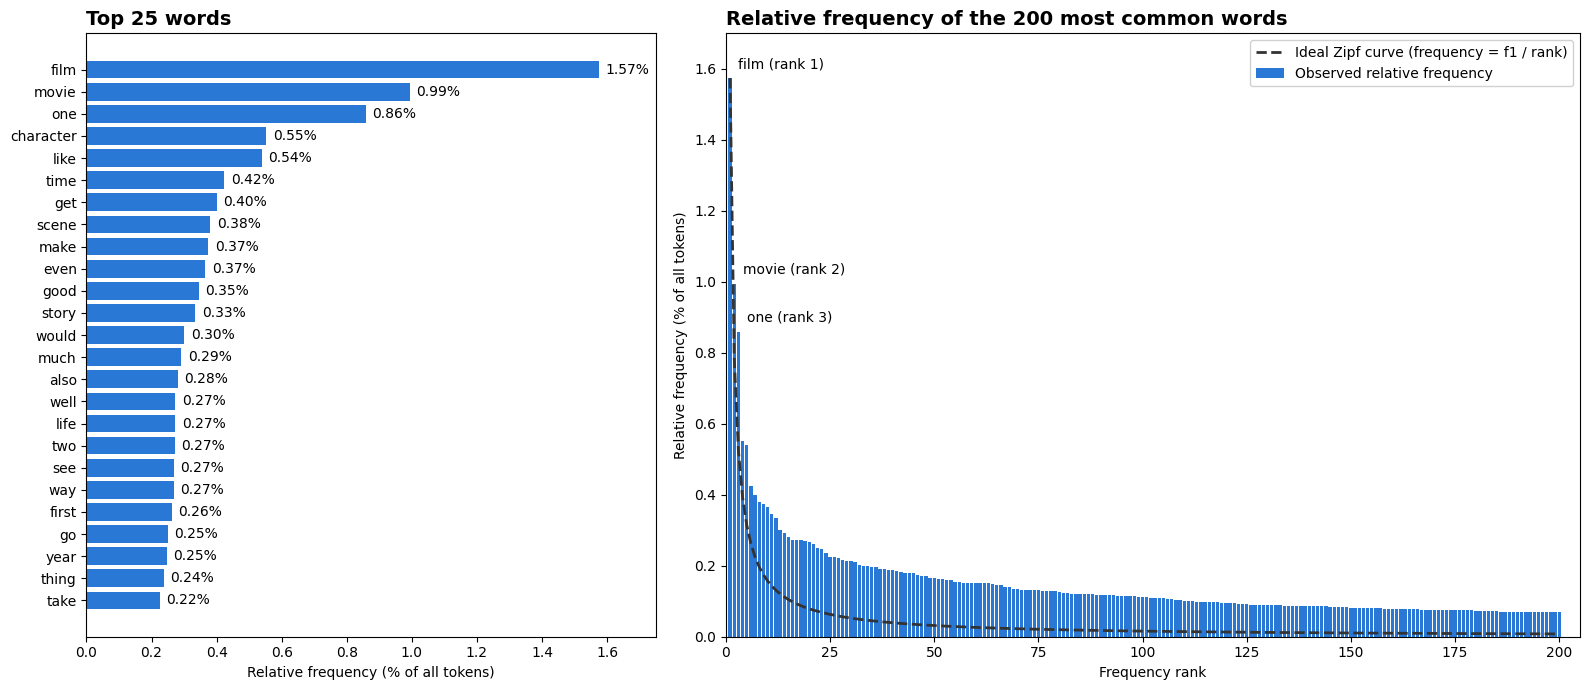

In [21]:
df = pd.read_csv('top200_words.csv')  # columns: rank, word, count
df['rel_freq'] = df['count'] / total_tokens
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1, 1.5]})

# ==========================================
# PLOT 1: Top 25 Words (Horizontal Bar Chart)
# ==========================================
top25 = df.head(25).iloc[::-1] # Reverse so rank 1 is at the top
bars1 = ax1.barh(top25['word'], top25['rel_freq'] * 100, color='#2a78d6')

ax1.set_title('Top 25 words', fontsize=14, fontweight='bold', loc='left')
ax1.set_xlabel('Relative frequency (% of all tokens)')
ax1.set_xlim(0, 1.75) # Give it a bit of room for labels

# Add the percentage labels to the end of each bar
for bar in bars1:
    width = bar.get_width()
    ax1.text(width + 0.02, bar.get_y() + bar.get_height()/2, 
             f'{width:.2f}%', 
             va='center', ha='left', fontsize=10)

# ==========================================
# PLOT 2: Zipf Plot (Vertical Bars + Curve)
# ==========================================
# Plot the observed data as vertical bars
# Multiply by 100 to show as percentage, matching the y-axis in your example
ax2.bar(df['rank'], df['rel_freq'] * 100, color='#2a78d6', width=0.8, label='Observed relative frequency')

# Calculate the Ideal Zipf curve: Frequency = f1 / rank
f1 = df['rel_freq'].iloc[0] * 100 # The % of the #1 word
ideal_zipf = f1 / df['rank']

# Plot the ideal Zipf curve as a dashed line
ax2.plot(df['rank'], ideal_zipf, color='#333333', linestyle='--', linewidth=2, label='Ideal Zipf curve (frequency = f1 / rank)')

# Add text annotations for the first 3 words
annotations = [(1, 'film (rank 1)'), (2, 'movie (rank 2)'), (3, 'one (rank 3)')]
for rank, text in annotations:
    y_val = df[df['rank'] == rank]['rel_freq'].values[0] * 100
    # Place the text slightly to the right and above the bar
    ax2.text(rank + 2, y_val + 0.02, text, fontsize=10, va='bottom')

ax2.set_title('Relative frequency of the 200 most common words', fontsize=14, fontweight='bold', loc='left')
ax2.set_xlabel('Frequency rank')
ax2.set_ylabel('Relative frequency (% of all tokens)')
ax2.set_xlim(0, 205)
ax2.set_ylim(0, 1.7)
ax2.legend(loc='upper right', framealpha=0.9)

# Clean up the layout
plt.tight_layout()
plt.savefig('combined_word_freq_plot.png', dpi=150)
plt.show()

**Left Plot: Top 25 Words**

**Domain Dominance:** The corpus is overwhelmingly driven by its topic. **"film" and "movie"** are by far the most frequent words, together making up nearly **2.6%** of all tokens in the entire corpus.

**Topic-Specific Vocabulary:** Words like **"character," "scene," "story," and "plot"** appear in the **top 15**. In a general English corpus, these would be pushed far down the list.

**Evaluative Language:** Words like "good," "bad," and "like" appear early, confirming that this is an opinion-based corpus (reviews).

**Stopword Leakage:** The presence of "one," "make," "get," "see," "go," "would," and "much" shows that standard stopword lists didn't catch everything, allowing high-frequency generic words to remain in the top ranks.

**Right Plot: Relative Frequency (Top 200) vs. Ideal Zipf**

**The "Ideal" vs. "Reality":** The dashed line represents pure Zipf's Law (where the #2 word should be exactly half the frequency of the #1 word). The blue bars represent your actual data.

**A Flatter Head:** Look at ranks 1 through 10. Your blue bars are much taller than the dashed curve. Because "film" (1.57%) and "movie" (0.99%) share the top spot, the drop-off is less severe than Zipf predicts.

**"The Long Tail" in Action:** By rank 50, the relative frequency of words drops below 0.2%, and by rank 200, it's almost zero. The visual "cliff" at the beginning is the classic heavy-head distribution of natural language.

**The Crossover Effect:** Because your top words don't dominate quite as aggressively as standard stopwords (like "the" or "of"), your blue bars remain consistently higher than the ideal Zipf curve all the way out to rank 200.

**Conclusion:** The corpus only loosely follows Zipf's Law. It has a long tail, but its head is too flat—a direct result of topic-specific vocabulary dominating the frequencies.

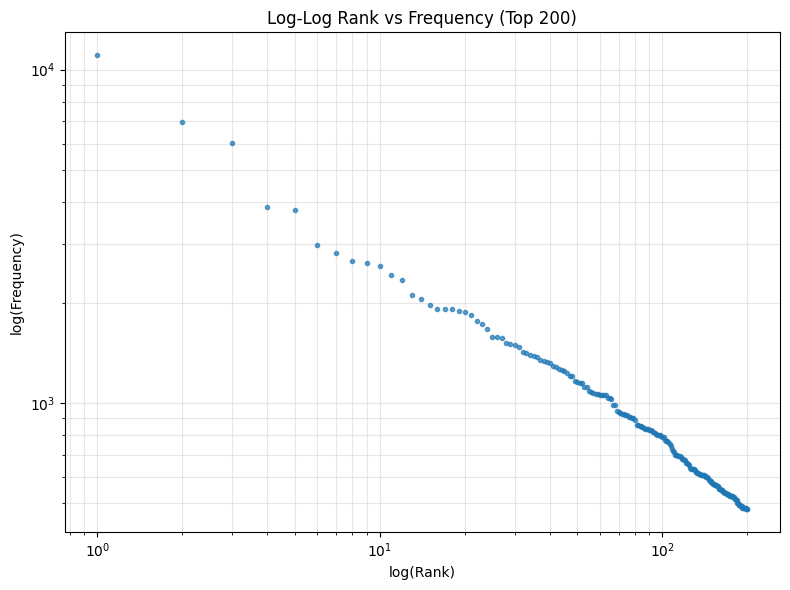

In [22]:

# --- Plot 1: log-log (Zipf preview) ---
plt.figure(figsize=(8, 6))
plt.loglog(df['rank'], df['count'], 'o', markersize=3, alpha=0.7)
plt.xlabel('log(Rank)')
plt.ylabel('log(Frequency)')
plt.title('Log-Log Rank vs Frequency (Top 200)')
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.savefig('top200_loglog.png', dpi=150)
plt.show()

**Why the linear scale is deceptive:** Because the drop is so extreme, a linear plot makes the tail look "flat." This is exactly why we need the log-log plot for Step 6—to see if that tail actually follows a straight-line decay (Zipf's law) or if it curves.

## Step 6: Does the observed relative frequency of these words follow Zipf’s law? Explain.

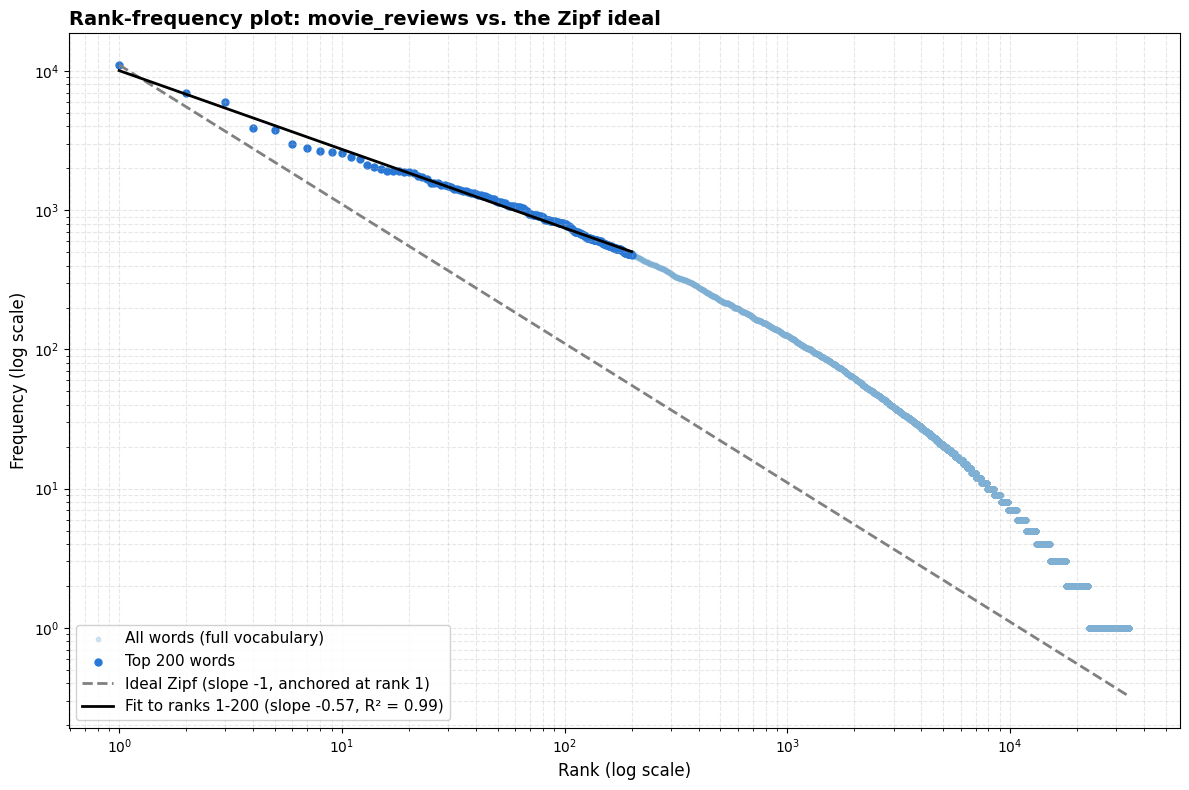

In [23]:
# 1. Prepare the data
# Get frequencies for ALL words, sorted from highest to lowest
all_counts = sorted(fdist.values(), reverse=True)
ranks = np.arange(1, len(all_counts) + 1)

# 2. Calculate the Ideal Zipf curve
# Zipf: Frequency = Constant / Rank. We anchor the constant to the #1 word.
f1 = all_counts[0]
ideal_zipf = f1 / ranks

# 3. Calculate the fit for the Top 200 words
# We extract the first 200 counts and fit a line to their log-log values
top200_counts = all_counts[:200]
top200_ranks = ranks[:200]
log_ranks_200 = np.log10(top200_ranks)
log_counts_200 = np.log10(top200_counts)

# np.polyfit returns [slope, intercept]
slope, intercept = np.polyfit(log_ranks_200, log_counts_200, 1)

# Calculate R-squared to show how good the fit is
predicted_log_counts = slope * log_ranks_200 + intercept
ss_res = np.sum((log_counts_200 - predicted_log_counts) ** 2)
ss_tot = np.sum((log_counts_200 - np.mean(log_counts_200)) ** 2)
r_squared = 1 - (ss_res / ss_tot)

# 4. Create the Plot
fig, ax = plt.subplots(figsize=(12, 8))

# Plot all words (faded light blue)
ax.scatter(ranks, all_counts, s=10, alpha=0.3, color='#7eb0d5', label='All words (full vocabulary)')

# Plot just the Top 200 words (solid blue)
ax.scatter(top200_ranks, top200_counts, s=25, color='#2a78d6', label='Top 200 words')

# Plot the Ideal Zipf curve (dashed grey)
ax.plot(ranks, ideal_zipf, linestyle='--', color='grey', linewidth=2, label='Ideal Zipf (slope -1, anchored at rank 1)')

# Plot the fitted line for the Top 200 (solid black)
fit_line = (10 ** intercept) * (top200_ranks ** slope)
ax.plot(top200_ranks, fit_line, color='black', linewidth=2, 
        label=f'Fit to ranks 1-200 (slope {slope:.2f}, R² = {r_squared:.2f})')

# Set logarithmic scales
ax.set_xscale('log')
ax.set_yscale('log')

# Formatting
ax.set_title('Rank-frequency plot: movie_reviews vs. the Zipf ideal', fontsize=14, fontweight='bold', loc='left')
ax.set_xlabel('Rank (log scale)', fontsize=12)
ax.set_ylabel('Frequency (log scale)', fontsize=12)

# Add gridlines for readability
ax.grid(True, which="both", ls="--", alpha=0.3)

# Add the legend
ax.legend(loc='lower left', fontsize=11, framealpha=0.9)

plt.tight_layout()
plt.savefig('zipf_full_vocab.png', dpi=150)
plt.show()

**Answer** Not strictly. The top 200 words follow a much flatter slope (~-0.57) than the ideal Zipf slope of -1.0

**Summary of the Rank-Frequency Plot**

**The Ideal vs. Observed:** The dashed grey line represents pure Zipf's Law (a perfect slope of -1.0). The solid black line is the actual fit for your top 200 words. Because the black line sits higher and is less steep (slope of -0.57), your corpus does not follow strict Zipf's Law.

**A "Flatter" Head:** In a standard English corpus, the most common words (like "the" and "of") are so incredibly dominant that the curve drops off a cliff at rank 2. Because you removed stopwords, your top words ("film", "movie", "character") share the frequency load much more evenly, creating a flatter, shallower slope at the top of the graph.

**The Impact of Synonyms:** The top two words, "film" and "movie," act as near-synonyms in this domain. Instead of one word hogging all the frequency, they split it, which pulls the start of the curve downward compared to the ideal, but keeps the rest of the curve flatter.

**The Long, Heavy Tail:** The light blue dots show the entire 34,000+ word vocabulary. Even though the slope is flat at the top, the corpus still exhibits the classic "long tail" of natural language, a massive number of words that appear only once or twice (seen in the flat cluster at the bottom right, where frequency = 1).

## Step 7: In what ways do you think the frequency of the words in this corpus differ from “all words in all corpora.”?

**Domain-specific vocabulary (The Head):** In a general corpus (like Wikipedia or the Brown Corpus), the most frequent words are almost all grammatical (the, of, and, to). In this corpus, the head is dominated by topic-specific content words **("film," "movie," "character," "scene," "plot")**.

**Evaluative/Opinion language:** Because these are reviews, we have see words that **express judgment ("good," "bad," "best," "great," "boring")** much higher up in the rankings than they would be in a neutral corpus.

**Absence of strict Zipfian distribution:** As Step 6 graph shows, the movie review corpus has a flatter head than the theoretical Zipf curve. A massive, balanced corpus (like "all words in all corpora") tends to align much closer to Zipf's law because the sheer variety of topics averages out the extreme topical spikes you see here.

**Genre markers:** Words like **" **actor," "director," "cast," "script," and "performance" are genre markers**. In a general corpus, these words would be buried deep in the long tail, but here they are in the top 50.

*In the Brown Corpus, function words occupy the top ~50 slots; here, only 3 of the top 10 ('one', 'like', 'would') are non-content words*

### Summary

The analysis of the movie review corpus reveals a classic "heavy head" distribution, though one that deviates from pure Zipf's law. Because stopwords were removed, the corpus is dominated by content words relating to the film industry and opinion ("film," "movie," "character," "good"). The top 200 words exhibited a relative frequency that dropped steeply from 1.57% ("film") to just 0.07% by rank 200.


When plotted on a log-log scale, the data displayed a shallower slope than the ideal Zipfian -1.0 reference line. This indicates that the corpus has a flatter distribution in its upper ranks than "all words in all corpora" would. This is a direct result of the corpus's specialized nature: general corpora are dominated by heavily skewed grammatical words (e.g., "the," "of"), whereas this corpus features a cluster of near-synonymous, topic-specific words sharing the highest frequencies. Ultimately, the assignment demonstrates how text preprocessing and domain context significantly shape the statistical distribution of words in a specialized corpus.

---------------